# 12. Polar coordinates: disks, drums and pipes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/12_polar_coordinates.ipynb)

*Companion to Chapter 11 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Pipes, rods, wires, shafts and drums are round. On a disk the natural coordinates are polar,
and the two families of spectral methods met so far fit them exactly: the angle is periodic, so
it gets a Fourier grid, and the radius is bounded, so it gets a Chebyshev grid. The one new
difficulty is the centre, where the polar form of the Laplacian divides by zero.

- the Laplacian in polar coordinates and why $r = 0$ is not a boundary
- a Chebyshev grid along the whole **diameter**, folded back onto $r > 0$
- the Laplacian on the disk from Kronecker products
- axisymmetric problems as one-dimensional problems in $r$

**Worked examples:** laminar flow in a pipe, the modes of a circular drum, a rod heated on
one side, the cooling of a long cylinder, and the Graetz problem of heat transfer to flow in a
tube, which gives the Nusselt number 3.657.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig, solve
from scipy.special import jn_zeros, jv

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

# fourier_diff2_matrix(N) from notebook 2
def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

theta = 2 * np.pi * np.arange(16) / 16
assert np.abs(fourier_diff2_matrix(16) @ np.cos(3 * theta) + 9 * np.cos(3 * theta)).max() < 1e-12

## 12.1 The Laplacian on a disk and the trouble at the centre

In polar coordinates $x = r\cos\theta$, $y = r\sin\theta$ the Laplacian is

$$\nabla^2 u = u_{rr} + \frac1r\,u_r + \frac{1}{r^2}\,u_{\theta\theta} .$$

The factors $1/r$ and $1/r^2$ are infinite at $r = 0$. Nothing physical happens there: the
centre of a pipe is a point like any other, and $\nabla^2u$ is perfectly finite. The
singularity belongs to the coordinates, which assign to one point all the angles at once.

The obvious choice, a Chebyshev grid on $0 \le r \le 1$, has two drawbacks.

- It has a point at $r = 0$, where an equation must be invented. A boundary condition
  "at $r = 0$" is the wrong idea: there is no boundary there.
- It clusters points near the centre, where the solution is smooth and nothing needs
  resolving. In the angular direction those rings of radius $\sim 1/N^2$ have a tiny arc
  length, which makes time-dependent problems extremely stiff (notebook 9).

**The remedy: discretize the diameter.** Let $r$ run over $[-1, 1]$. The points $(r, \theta)$
and $(-r, \theta + \pi)$ are the same physical point, so

$$u(-r, \theta) = u(r, \theta + \pi).$$

Along any diameter the solution is a smooth function of $r \in [-1, 1]$, the ideal setting
for a Chebyshev grid, and the grid now clusters only at the wall $r = \pm1$, where boundary
layers live. Taking **$N$ odd** puts no grid point at $r = 0$, so the division by $r$ never
sees zero. The price is that every point of the disk appears twice. Section 12.2 removes the
duplicates.

## 12.2 Folding the diameter: the axisymmetric case

Start with functions that do not depend on $\theta$, so that $u(-r) = u(r)$ and
$\nabla^2u = u'' + u'/r$.

**By hand.** Number the Chebyshev points $r_0 = 1 > r_1 > \dots > r_N = -1$. Because $N$ is
odd they come in mirror pairs, $r_{N-i} = -r_i$. With $n = (N-1)/2$:

| index | $0$ | $1, \dots, n$ | $n+1, \dots, N-1$ | $N$ |
| --- | --- | --- | --- | --- |
| point | wall, $r = 1$ | interior, $r > 0$ | mirror images, $r < 0$ | wall, $r = -1$ |

Let $A = D^2 + \operatorname{diag}(1/r)\,D$ be the operator on the whole diameter. Row $i$ of
$A\mathbf{u}$ is $\sum_j A_{ij}u_j$. For an even function the value at a mirror point $N - j$
equals the value at $j$, so the two columns can be added:

$$(A\mathbf{u})_i = \sum_{j=1}^{n}\big(A_{ij} + A_{i,N-j}\big)\,u_j + \text{(wall terms)},\qquad i = 1, \dots, n .$$

The unknowns are now only the $n$ values at $r > 0$. In matrix terms: take the block $E_1$ of
$A$ with rows and columns $1..n$, take the block $E_2$ with rows $1..n$ and columns
$N-1, N-2, \dots, n+1$ (the mirror columns, **in reversed order** so that they line up), and
use $E_1 + E_2$.

In [3]:
def radial_blocks(N):
    """Blocks of u_rr + u_r/r on the diameter grid (N odd), for rows at the interior points r > 0.

    Returns E1 (acting on values at r_i > 0), E2 (acting on their mirror images at -r_i),
    the radii r_1 > ... > r_n > 0, and the two wall columns (for r = +1 and r = -1).
    """
    if N % 2 == 0:
        raise ValueError("N must be odd, so that r = 0 is not a grid point")
    D, r = cheb(N)
    A = D @ D + np.diag(1 / r) @ D
    n = (N - 1) // 2
    pos = np.arange(1, n + 1)                 # indices of the interior points with r > 0
    neg = N - pos                             # indices of their mirror images, r_{N-i} = -r_i
    return A[np.ix_(pos, pos)], A[np.ix_(pos, neg)], r[pos], A[pos, 0], A[pos, N]

E1, E2, r, _, _ = radial_blocks(5)
print("diameter grid for N = 5:", np.round(cheb(5)[1], 4))
print("kept points r > 0:      ", np.round(r, 4))
print("folded operator E1 + E2:")
print(np.round(E1 + E2, 3))

diameter grid for N = 5: [ 1.     0.809  0.309 -0.309 -0.809 -1.   ]
kept points r > 0:       [0.809 0.309]
folded operator E1 + E2:
[[-31.533   7.622]
 [ 14.778 -10.067]]


**Verify** the small example. For $u = 1 - r^2$ the exact result is
$u'' + u'/r = -2 - 2 = -4$ at every point. The function vanishes at the wall, so the wall
terms are zero.

In [4]:
print("(E1 + E2) applied to 1 - r²:", (E1 + E2) @ (1 - r**2))
assert np.allclose((E1 + E2) @ (1 - r**2), -4)

(E1 + E2) applied to 1 - r²: [-4. -4.]


**Worked example: flow in a pipe.** Fully developed laminar flow in a round pipe obeys
$\nabla^2u = -1$ with $u = 0$ at the wall (velocity in units of $GR^2/\mu$, with $G$ the
pressure gradient). The exact solution is the Poiseuille paraboloid $u = (1 - r^2)/4$. The same
problem describes the torsion of a round shaft.

In [5]:
E1, E2, r, _, _ = radial_blocks(11)
u = solve(E1 + E2, -np.ones(len(r)))
print(f"largest error against (1 - r²)/4: {np.abs(u - (1 - r**2) / 4).max():.1e}")
assert np.abs(u - (1 - r**2) / 4).max() < 1e-13

largest error against (1 - r²)/4: 5.6e-17


The solution is a polynomial of degree 2, so it is found to rounding error with any $N$. A
harder test follows in 12.6.

## 12.3 The Laplacian on the whole disk

Now let $u$ depend on $\theta$ too. Use the Fourier grid $\theta_j = 2\pi j/M$ with $M$ even,
so that $\theta_j + \pi$ is again a grid point, $M/2$ places further on.

**By hand.** The unknowns are $U_{ij} = u(r_i, \theta_j)$ for $i = 1..n$ (so $r_i > 0$) and
$j = 0..M-1$, strung out row by row as in notebook 6: the angle index runs fastest. The value
at a mirror point is no longer the value at the same angle but the one **half a turn away**:

$$u(-r_i, \theta_j) = u(r_i, \theta_{j + M/2}).$$

So $E_1$ acts on each ray as it stands, and $E_2$ acts on the data shifted by $M/2$ in the
angle. If $P$ is the $M\times M$ permutation matrix of that shift and $D^{(2)}_\theta$ the
Fourier second-derivative matrix, the three terms of the Laplacian are

$$L = \underbrace{E_1\otimes I + E_2\otimes P}_{u_{rr} + u_r/r}
    \;+\; \underbrace{\operatorname{diag}(1/r_i^2)\otimes D^{(2)}_\theta}_{u_{\theta\theta}/r^2} .$$

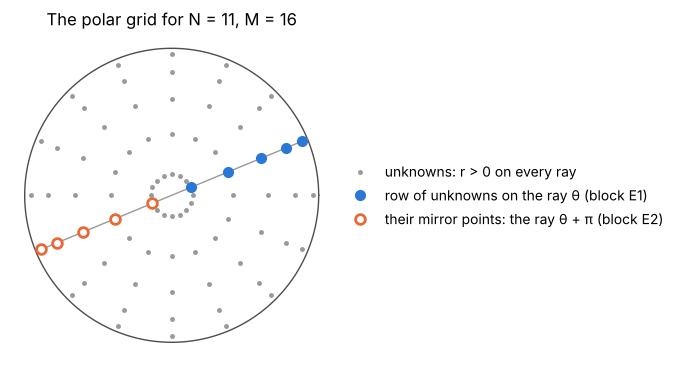

In [6]:
def disk_laplacian(N, M):
    """Laplacian on the unit disk for u = 0 at r = 1. N odd (Chebyshev, diameter), M even (Fourier).

    Unknowns U[i, j] = u(r_i, θ_j), flattened row by row. Returns L, r (the n = (N-1)/2 radii) and θ.
    """
    E1, E2, r, _, _ = radial_blocks(N)
    theta = 2 * np.pi * np.arange(M) / M
    I = np.eye(M)
    P = np.roll(I, M // 2, axis=1)            # (P g)_j = g_{j + M/2}: the value half a turn away
    L = np.kron(E1, I) + np.kron(E2, P) + np.kron(np.diag(1 / r**2), fourier_diff2_matrix(M))
    return L, r, theta

def disk_grid(r, theta):
    return np.meshgrid(r, theta, indexing="ij")           # R[i, j] = r_i, T[i, j] = θ_j

# the grid for N = 11, M = 16, and the two rays that make up one diameter
_, r_small, theta_small = disk_laplacian(11, 16)
R_small, T_small = disk_grid(r_small, theta_small)
ray = theta_small[1]
fig, ax = plt.subplots(figsize=(6.6, 4.2))
ax.plot(np.cos(np.linspace(0, 2 * np.pi, 200)), np.sin(np.linspace(0, 2 * np.pi, 200)), color="0.3", lw=1)
ax.plot([-np.cos(ray), np.cos(ray)], [-np.sin(ray), np.sin(ray)], color="0.6", lw=1)
ax.plot((R_small * np.cos(T_small)).flatten(), (R_small * np.sin(T_small)).flatten(), ".", color="0.6", ms=5, label="unknowns: r > 0 on every ray")
ax.plot(r_small * np.cos(ray), r_small * np.sin(ray), "o", ms=7, label="row of unknowns on the ray θ (block E1)")
ax.plot(-r_small * np.cos(ray), -r_small * np.sin(ray), "o", ms=7, mfc="w", mew=2, label="their mirror points: the ray θ + π (block E2)")
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("The polar grid for N = 11, M = 16")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**Verify** in two ways. First on a function that depends on both coordinates:
$u = (1 - r^2)\,r^3\cos3\theta$ vanishes on the rim, and since $r^3\cos3\theta$ is harmonic and
$\nabla^2(r^5\cos3\theta) = (25 - 9)\,r^3\cos3\theta$, its Laplacian is $-16\,r^3\cos3\theta$.
Then the pipe flow problem again, now solved on the full disk.

In [7]:
N, M = 31, 24
L, r, theta = disk_laplacian(N, M)
R, T = disk_grid(r, theta)
print(f"N = {N}, M = {M}: {len(r)} radii x {M} angles = {L.shape[0]} unknowns")

u = (1 - R**2) * R**3 * np.cos(3 * T)
operator_error = np.abs(L @ u.flatten() + (16 * R**3 * np.cos(3 * T)).flatten()).max()
u_pipe = solve(L, -np.ones(L.shape[0])).reshape(R.shape)
pipe_error = np.abs(u_pipe - (1 - R**2) / 4).max()
print(f"operator applied to (1 - r²) r³ cos 3θ: error {operator_error:.1e}")
print(f"pipe flow on the full disk: error {pipe_error:.1e}")
assert operator_error < 1e-9 and pipe_error < 1e-10

N = 31, M = 24: 15 radii x 24 angles = 360 unknowns
operator applied to (1 - r²) r³ cos 3θ: error 1.0e-12
pipe flow on the full disk: error 1.9e-14


## 12.4 Worked example: the modes of a drum

**Problem.** A circular membrane of radius 1, clamped at its rim, vibrates in modes
$u(r, \theta)\cos(\omega t)$ with $\nabla^2u = -\lambda u$ and $\lambda = \omega^2$ (in units
where the wave speed is 1). Find the frequencies and the shapes.

**By hand.** Separation of variables, $u = f(r)\cos m\theta$, gives Bessel's equation for $f$.
The solution that is finite at the centre is $J_m(\sqrt\lambda\,r)$, and the rim condition
requires $\sqrt\lambda$ to be a zero of $J_m$:

$$\lambda = j_{m,k}^2,\qquad u = J_m(j_{m,k}\,r)\,\begin{cases}\cos m\theta\\ \sin m\theta\end{cases}$$

For $m = 0$ the mode is axisymmetric and the eigenvalue is simple. For $m \ge 1$ the cosine and
sine versions have the same frequency, so the eigenvalue is **double**. The lowest values are
$j_{0,1} = 2.404826$, $j_{1,1} = 3.831706$, $j_{2,1} = 5.135622$, $j_{0,2} = 5.520078$.

**Verify.** The matrix eigenvalues must reproduce this list, with the multiplicities.

In [8]:
computed, vectors = eig(-L)
order = np.argsort(computed.real)
computed, vectors = computed[order], vectors[:, order]

exact = sorted((zero**2, m, k + 1) for m in range(9) for k, zero in enumerate(jn_zeros(m, 4))
               for copy in range(1 if m == 0 else 2))          # (λ, m, k), each m ≥ 1 listed twice
count = 17                                                       # the first ten distinct eigenvalues
print("   m  k    j_mk      exact λ       computed λ      error")
for (value, m, kk), lam in zip(exact[:count], computed[:count]):
    print(f"  {m:2d} {kk:2d}  {np.sqrt(value):.6f}  {value:11.7f}  {lam.real:14.10f}  {abs(lam - value):8.1e}")
eigen_error = np.abs(computed[:count] - np.array([value for value, _, _ in exact[:count]])).max()
assert eigen_error < 1e-8
assert np.sum(np.diff(computed[:count].real) > 1e-6) + 1 == 10   # the computed pairs coincide: ten distinct values

   m  k    j_mk      exact λ       computed λ      error
   0  1  2.404826    5.7831860    5.7831859630   3.4e-12
   1  1  3.831706   14.6819706   14.6819706421   2.5e-12
   1  1  3.831706   14.6819706   14.6819706421   1.2e-12
   2  1  5.135622   26.3746164   26.3746164272   2.9e-12
   2  1  5.135622   26.3746164   26.3746164272   2.3e-13
   0  2  5.520078   30.4712623   30.4712623437   1.9e-12
   3  1  6.380162   40.7064658   40.7064658182   4.5e-12
   3  1  6.380162   40.7064658   40.7064658182   8.2e-13
   1  2  7.015587   49.2184563   49.2184563217   5.5e-12
   1  2  7.015587   49.2184563   49.2184563217   2.3e-13
   4  1  7.588342   57.5829409   57.5829409033   1.8e-12
   4  1  7.588342   57.5829409   57.5829409033   4.0e-13
   2  2  8.417244   70.8499989   70.8499989191   2.8e-14
   2  2  8.417244   70.8499989   70.8499989191   9.1e-13
   0  3  8.653728   74.8870068   74.8870067907   4.3e-14
   5  1  8.771484   76.9389283   76.9389283336   5.7e-13
   5  1  8.771484   76.9389283 

Ten distinct frequencies, seventeen eigenvalues counting the double ones, all correct to ten
digits or more from a matrix of size 360.

**Drawing on the disk.** The computational grid is coarse, with only 15 radii, and has no
point at the centre. For a picture the solution is evaluated on a finer polar grid: along each
diameter by the barycentric formula of notebook 4 (written here as a matrix), and in the angle
with `fourier_interpolate`, the zero padding of notebook 2. Both are exact evaluations of the
interpolant that the method is built on, so the picture shows what was computed and nothing
else.

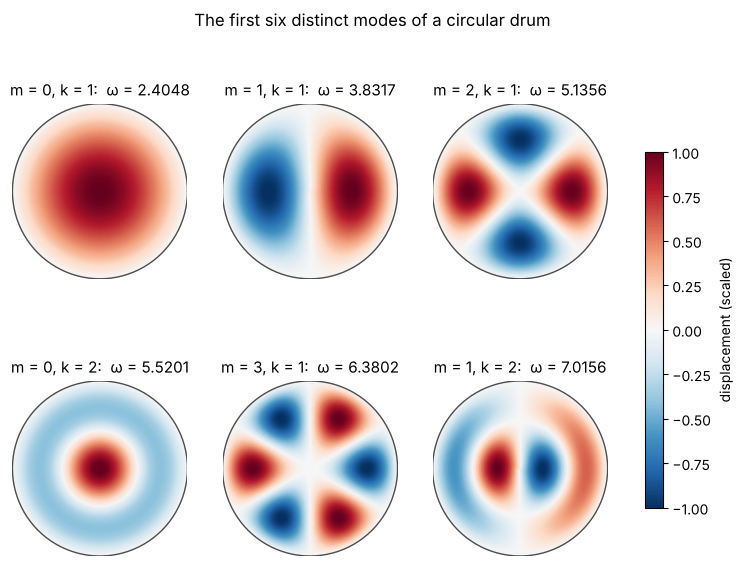

In [9]:
# fourier_interpolate(v, M) from notebook 2
def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

def barycentric_matrix(N, x_eval):
    """Matrix B with B @ values = the interpolant through values at the N+1 Chebyshev points, evaluated at x_eval."""
    j = np.arange(N + 1)
    w = (-1.0) ** j
    w[[0, N]] /= 2
    difference = np.asarray(x_eval, dtype=float)[:, None] - np.cos(np.pi * j / N)[None, :]
    ratio = w / np.where(difference == 0, 1e-300, difference)       # at a grid point that one term dominates
    return ratio / ratio.sum(axis=1, keepdims=True)

def disk_plot(ax, U, rim=0.0, levels=None, fine=(60, 192), **kwargs):
    """Colour plot on the unit disk of U[i, j] = u(r_i, θ_j); `rim` is a number or an array of rim values over θ."""
    n, M = U.shape
    rim_values = np.broadcast_to(np.asarray(rim, dtype=float), (M,))
    half_turn = lambda V: np.roll(V, -M // 2, axis=-1)                # values at θ + π
    diameter = np.vstack([rim_values, U, half_turn(U)[::-1], half_turn(rim_values)])   # all N+1 points of each diameter
    r_fine = np.linspace(0, 1, fine[0])
    V = barycentric_matrix(2 * n + 1, r_fine) @ diameter              # finer in r
    V = np.array([fourier_interpolate(ring, fine[1]) for ring in V])  # finer in θ, one ring at a time
    V = np.hstack([V, V[:, :1]])                                      # repeat θ = 0 at θ = 2π
    angle = 2 * np.pi * np.arange(fine[1] + 1) / fine[1]
    X, Y = r_fine[:, None] * np.cos(angle), r_fine[:, None] * np.sin(angle)
    mesh = ax.pcolormesh(X, Y, V, shading="gouraud", rasterized=True, **kwargs)
    if levels is not None:
        ax.contour(X, Y, V, levels=levels, colors="w", linewidths=0.8)
    ax.plot(np.cos(angle), np.sin(angle), color="0.3", lw=1)
    ax.set_aspect("equal")
    ax.axis("off")
    return mesh

distinct = [0, 1, 3, 5, 6, 8]                 # positions of the first six distinct eigenvalues in the sorted list
fig, axes = plt.subplots(2, 3, figsize=(9.6, 6.6))
for ax, index in zip(axes.flat, distinct):
    mode = vectors[:, index].real.reshape(R.shape)
    mode = mode / mode.flat[np.abs(mode).argmax()]              # scale so that the largest value is +1
    mesh = disk_plot(ax, mode, cmap="RdBu_r", vmin=-1, vmax=1)
    value, m, kk = exact[index]
    ax.set_title(f"m = {m}, k = {kk}:  ω = {np.sqrt(computed[index].real):.4f}", fontsize=11)
fig.suptitle("The first six distinct modes of a circular drum", y=0.98)
fig.colorbar(mesh, ax=axes, shrink=0.7, label="displacement (scaled)");

The index $m$ counts the nodal diameters and $k - 1$ the nodal circles. (For a double
eigenvalue the solver returns one member of the pair at an arbitrary rotation.)

**What it means.** The frequencies of a string are multiples of the lowest one, which is why a
string has a clear pitch. The drum frequencies are in the ratios
$1 : 1.593 : 2.136 : 2.295 : \dots$, set by the Bessel zeros and not harmonic, which is why a
drum sounds like a thump (exercise 1). The same eigenvalues give the cut-off frequencies of a
circular waveguide and the decay rates of heat conduction in a cylinder (12.6).

## 12.5 Worked example: a rod heated on one side

**Problem.** The cross-section of a long rod is the unit disk. Its surface temperature is held
at a distribution that is hot on one side,

$$u(1, \theta) = g(\theta) = \frac{1 - a^2}{1 - 2a\cos\theta + a^2},\qquad a = \tfrac12 ,$$

which peaks at $g(0) = 3$, falls to $g(\pi) = \tfrac13$ and has mean 1. Find the steady
temperature inside, $\nabla^2u = 0$.

**By hand.** Each angular harmonic of the rim data extends into the disk on its own:
$r^m\cos m\theta$ is harmonic. The function $g$ is the geometric series
$1 + 2\sum_{m\ge1}a^m\cos m\theta$, so

$$u(r, \theta) = 1 + 2\sum_{m\ge1}(ar)^m\cos m\theta = \frac{1 - a^2r^2}{1 - 2ar\cos\theta + a^2r^2} .$$

**Boundary values that are not zero.** As in notebook 6, the known wall values multiply the
wall columns of the operator and move to the right-hand side. There are two wall columns per
ray: column 0 multiplies the rim value at $\theta_j$, and column $N$, the far end of the
diameter, multiplies the rim value at $\theta_j + \pi$.

largest error: 2.1e-11    temperature at the centre: 1.0000000000
with N = 21 and the same M = 64: largest error 2.0e-11


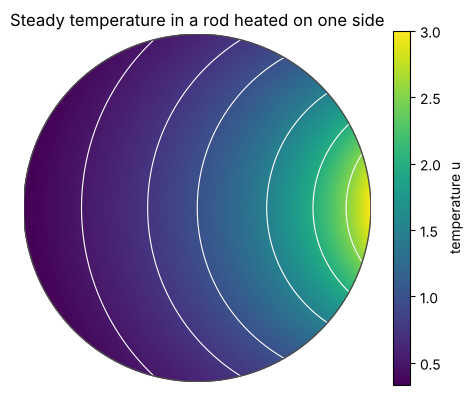

In [10]:
def solve_laplace_disk(g, N, M):
    """Solve ∇²u = 0 on the unit disk with u(1, θ) = g(θ). Returns U[i, j], r and θ."""
    L, r, theta = disk_laplacian(N, M)
    _, _, _, wall_plus, wall_minus = radial_blocks(N)
    rim = g(theta)
    rhs = -(np.kron(wall_plus, rim) + np.kron(wall_minus, np.roll(rim, -M // 2)))    # rim value at θ and at θ + π
    return solve(L, rhs).reshape(len(r), M), r, theta

U, r3, theta3 = solve_laplace_disk(lambda t: np.cos(3 * t), 15, 16)                    # a first check: r³ cos 3θ
assert np.abs(U - r3[:, None] ** 3 * np.cos(3 * theta3)).max() < 1e-12

a = 0.5
g = lambda t: (1 - a**2) / (1 - 2 * a * np.cos(t) + a**2)
U, r_hot, theta_hot = solve_laplace_disk(g, 33, 64)
R_hot, T_hot = disk_grid(r_hot, theta_hot)
hot_exact = lambda R, T: (1 - a**2 * R**2) / (1 - 2 * a * R * np.cos(T) + a**2 * R**2)
exact_hot = hot_exact(R_hot, T_hot)
centre = (barycentric_matrix(33, [0.0]) @ np.concatenate([[g(0.0)], U[:, 0], U[::-1, 32], [g(np.pi)]]))[0]
print(f"largest error: {np.abs(U - exact_hot).max():.1e}    temperature at the centre: {centre:.10f}")
assert np.abs(U - exact_hot).max() < 1e-9 and abs(centre - 1) < 1e-9
U_21, r_21, theta_21 = solve_laplace_disk(g, 21, 64)                                   # fewer radial points, same angles
error_21 = np.abs(U_21 - hot_exact(*disk_grid(r_21, theta_21))).max()
print(f"with N = 21 and the same M = 64: largest error {error_21:.1e}")
assert error_21 < 1e-9

fig, ax = plt.subplots(figsize=(5.6, 4.6))
mesh = disk_plot(ax, U, rim=g(theta_hot), levels=[0.5, 0.75, 1.0, 1.5, 2.0, 2.5], cmap="viridis")
ax.set_title("Steady temperature in a rod heated on one side")
fig.colorbar(mesh, label="temperature u");

**What it means.** The factor $r^m$ damps the $m$-th harmonic of the surface temperature on the
way in: a pattern with angular wavelength $2\pi/m$ penetrates to a depth of about $1/m$ of the
radius. The sharp hot spot on the surface is therefore a broad, mild warming at mid-radius,
and the centre feels only the mean, $u(0) = 1$. The same reasoning tells a designer how deep
the thermal stresses from uneven surface heating reach.

The resolution needed is set by the rim data: its harmonics decay like $a^m = 2^{-m}$, so
$M = 64$ angles carry them down to $2^{-32} \approx 10^{-10}$. With $N = 33$ every $r^m$ up
to $m = M/2$ is a polynomial that the radial grid represents exactly. That is more than
necessary: $N = 21$ gives the same error, because the harmonics it cannot represent exactly
have amplitudes below $10^{-6}$ and are still approximated well.

## 12.6 Axisymmetric problems: the cooling of a cylinder

When neither the data nor the geometry depends on $\theta$, the folded radial operator
$E_1 + E_2$ of 12.2 is all that is needed.

**Problem.** A long hot cylinder is plunged into a well-stirred bath that holds its surface at
the bath temperature. With time in units of $R^2/\alpha$ the temperature excess obeys
$u_t = u_{rr} + u_r/r$, $u(1, t) = 0$. At late times it decays like $e^{-\lambda_1t}$. Find
$\lambda_1$.

**By hand.** This is the $m = 0$ family of the drum: $\lambda_k = j_{0,k}^2$, with
eigenfunctions $J_0(j_{0,k}\,r)$. The slowest rate is $j_{0,1}^2 = 5.783186$.

In [11]:
def radial_operator(N):
    """u'' + u'/r on the points r_1 > ... > r_n > 0 for even functions with u(1) = 0. Returns the matrix and r."""
    E1, E2, r, _, _ = radial_blocks(N)
    return E1 + E2, r

Lr, r = radial_operator(25)
values, modes = eig(-Lr)
order = np.argsort(values.real)
values, modes = values[order].real, modes[:, order].real
j0 = jn_zeros(0, 3)
print("decay rates:", np.round(values[:3], 8), "   exact j_0k²:", np.round(j0**2, 8))
assert abs(values[0] - 5.783186) < 1e-6 and np.abs(values[:3] - j0**2).max() < 1e-8

shape = modes[:, 0] / modes[-1, 0] * jv(0, j0[0] * r[-1])        # scale to match J0 at the innermost point
assert np.abs(shape - jv(0, j0[0] * r)).max() < 1e-10
R_steel, alpha_steel = 0.025, 1.2e-5
print(f"steel bar of radius 25 mm: time constant R²/(λ1 α) = {R_steel**2 / (values[0] * alpha_steel):.1f} s")

decay rates: [ 5.78318596 30.47126234 74.88700679]    exact j_0k²: [ 5.78318596 30.47126234 74.88700679]
steel bar of radius 25 mm: time constant R²/(λ1 α) = 9.0 s


Twelve unknowns give the decay rate and the Bessel function $J_0$ to ten digits, with no
special treatment of the centre. For an engineer $\lambda_1$ is the number behind the
one-term approximation of the transient conduction charts: after a short initial period the
temperature everywhere in the cylinder falls by a factor $e$ every $R^2/(5.783\,\alpha)$,
which is 9 seconds for a steel bar 50 mm in diameter.

## 12.7 Worked example: the Graetz problem

**Problem.** Fluid in fully developed laminar flow, at uniform temperature $T_0$, enters a
section of tube whose wall is held at $T_w$. How fast does the fluid approach the wall
temperature, and what is the heat transfer coefficient far downstream? This is the classic
model of a laminar-flow heat exchanger tube.

**By hand.** Follow a ring of fluid. Heat is carried along the tube by the flow, with the
parabolic velocity $2\bar u\,(1 - r^2/R^2)$, and conducted radially. Conduction along the axis
is neglected, which is justified when the Péclet number $Pe = 2R\bar u/\alpha$ is large. The
energy balance is

$$2\bar u\Big(1 - \frac{r^2}{R^2}\Big)\frac{\partial T}{\partial z} = \frac{\alpha}{r}\frac{\partial}{\partial r}\Big(r\frac{\partial T}{\partial r}\Big).$$

With $\xi = r/R$, $\zeta = z/(R\,Pe)$ and $\Theta = (T - T_w)/(T_0 - T_w)$ this becomes
$(1 - \xi^2)\,\Theta_\zeta = \Theta_{\xi\xi} + \Theta_\xi/\xi$. It looks like the cooling
cylinder with $\zeta$ in the role of time, except that fluid near the wall moves slowly and so
"ages" faster. Separation of variables, $\Theta = \sum_k c_k\,\phi_k(\xi)\,e^{-\lambda_k^2\zeta}$,
gives the eigenvalue problem

$$\phi'' + \frac1\xi\,\phi' + \lambda^2(1 - \xi^2)\,\phi = 0,\qquad \phi(1) = 0,\quad \phi \text{ regular at } \xi = 0 .$$

The weight $1 - \xi^2$ spoils the Bessel solution; Graetz solved the problem by series in 1883.
In matrix form it is a **generalized** eigenproblem, $-L_r\boldsymbol\phi = \lambda^2 W\boldsymbol\phi$
with $W = \operatorname{diag}(1 - \xi_i^2)$, of the kind met in notebook 8.

**The Nusselt number.** Far downstream only the first mode survives, so every temperature
difference decays like $e^{-\lambda_1^2\zeta}$. Integrate the equation over the cross-section
with the weight $\xi$: the left side is the rate of change of the flow-weighted (bulk)
temperature $\Theta_b = 4\int_0^1(1 - \xi^2)\,\Theta\,\xi\,d\xi$, and the right side is the wall
gradient, so $d\Theta_b/d\zeta = 4\,\Theta_\xi(1)$. With $d\Theta_b/d\zeta = -\lambda_1^2\Theta_b$
this gives $-\Theta_\xi(1)/\Theta_b = \lambda_1^2/4$, and therefore

$$Nu = \frac{h\,(2R)}{k} = \frac{-2\,\Theta_\xi(1)}{\Theta_b} = \frac{\lambda_1^2}{2} .$$

In [12]:
def graetz(N):
    """Eigenvalues λ_k (ascending) and eigenfunctions of the Graetz problem on the grid of radial_operator(N)."""
    Lr, xi = radial_operator(N)
    squares, phi = eig(-Lr, np.diag(1 - xi**2))
    order = np.argsort(squares.real)
    return np.sqrt(squares[order].real), phi[:, order].real, xi

published = np.array([2.7043644, 6.6790315, 10.6733795])
print("  N     λ1           λ2           λ3           Nu")
for N in (11, 17, 25, 33, 41):
    lam_N = graetz(N)[0]
    print(f"{N:3d}  {lam_N[0]:.8f}  {lam_N[1]:.8f}  {lam_N[2]:.8f}   {lam_N[0]**2 / 2:.6f}")
lam, phi, xi = graetz(33)
assert np.abs(lam[:3] - published).max() < 1e-7
assert np.abs(lam[:3] - lam_N[:3]).max() < 1e-8               # N = 33 against N = 41: the values no longer move
Nu = lam[0] ** 2 / 2
assert abs(Nu - 3.657) < 5e-4 and abs(Nu - 3.6568) < 1e-5

  N     λ1           λ2           λ3           Nu
 11  2.70434598  6.65272143  10.58903401   3.656744
 17  2.70436442  6.67900162  10.66539526   3.656793
 25  2.70436442  6.67903145  10.67337729   3.656793
 33  2.70436442  6.67903145  10.67337954   3.656793
 41  2.70436442  6.67903145  10.67337954   3.656793


The three eigenvalues agree with the published values to within one unit in the last digit
quoted, they no longer change when $N$ is raised from 33 to 41, and
$Nu = \lambda_1^2/2 = 3.657$, the number in every heat transfer textbook for laminar flow in a
tube with constant wall temperature.

second mode relative to the first at ζ = 0.1: factor 0.024


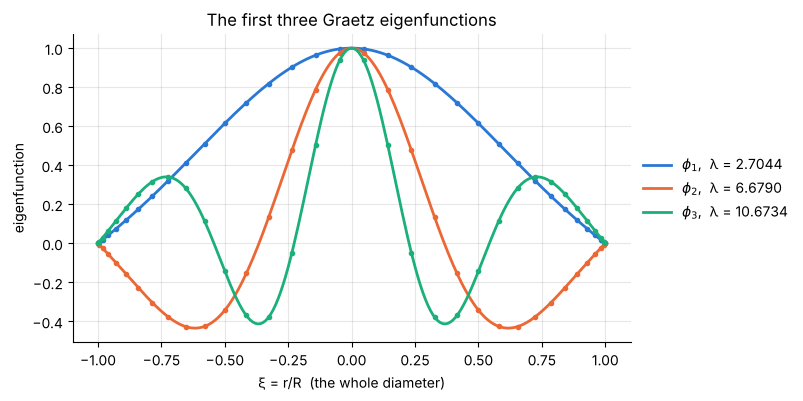

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 4))
xi_fine = np.linspace(-1, 1, 201)
B = barycentric_matrix(33, xi_fine)
for kk in range(3):
    on_diameter = np.concatenate([[0.0], phi[:, kk], phi[::-1, kk], [0.0]])    # the whole diameter, by symmetry
    profile = B @ on_diameter
    scale = profile[100]                                                       # the value at the centre
    line, = ax.plot(xi_fine, profile / scale, label=f"$\\phi_{kk + 1}$,  λ = {lam[kk]:.4f}")
    ax.plot(cheb(33)[1], on_diameter / scale, "o", ms=3, color=line.get_color())
ax.set(xlabel="ξ = r/R  (the whole diameter)", ylabel="eigenfunction", title="The first three Graetz eigenfunctions")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

entry = np.exp(-(lam[1] ** 2 - lam[0] ** 2) * 0.1)
print(f"second mode relative to the first at ζ = 0.1: factor {entry:.3f}")
assert 0.02 < entry < 0.03

**What it means.** The first eigenfunction is the fully developed temperature profile. The
higher ones describe the thermal entrance region and die out quickly: relative to the first
mode the second has decayed by $e^{-(\lambda_2^2 - \lambda_1^2)\zeta}$, which is down to 2 % at
$\zeta = 0.1$. In dimensional terms $\zeta = 0.1$ is $z/D = 0.05\,Pe$, the usual
estimate of the thermal entrance length, $0.05\,Re\,Pr$ diameters. Beyond it the heat transfer
coefficient is constant at $h = 3.657\,k/D$, independent of the flow rate.

## Summary

- The singularity of the polar Laplacian at $r = 0$ belongs to the coordinates. No boundary
  condition is imposed there.
- Put the Chebyshev grid on the diameter $-1 \le r \le 1$ with $N$ odd, and use
  $u(-r, \theta) = u(r, \theta + \pi)$ to fold the operator onto $r > 0$: the block $E_1$ acts
  on the data, the mirror block $E_2$ on the data half a turn away.
- On the disk, $L = E_1\otimes I + E_2\otimes P + \operatorname{diag}(1/r^2)\otimes D^{(2)}_\theta$.
  For axisymmetric problems, $L_r = E_1 + E_2$.
- Non-zero rim values enter through two wall columns per ray, one for $\theta$ and one for
  $\theta + \pi$.
- A few dozen unknowns reproduce Bessel zeros, the Graetz eigenvalues and $Nu = 3.657$ to
  seven digits or more.

## Exercises

1. **Why a drum has no pitch.** With `disk_laplacian(31, 24)` compute the first six distinct
   frequencies $\omega = \sqrt\lambda$ of the drum and their ratios to the lowest one. Compare
   with the ratios $1 : 2 : 3 : \dots$ of a string. Then find, by trial, the smallest odd $N$
   (keeping $M = 24$) for which the first seventeen eigenvalues are all correct to $10^{-7}$.
2. **Start-up of pipe flow.** A fluid at rest in a pipe is set in motion at $t = 0$ by a
   constant pressure gradient. In units of $R^2/\nu$ for time the velocity obeys
   $u_t = 1 + u_{rr} + u_r/r$ with $u(1, t) = 0$ and $u(r, 0) = 0$, and tends to
   $(1 - r^2)/4$. Using `radial_operator(25)`, find the time at which the centreline velocity
   reaches 99 % of its final value $\tfrac14$. Suggestions: write $u$ as the steady solution
   minus a transient, expand the transient in the eigenvectors of the matrix, and find the
   centreline value by evaluating the interpolant of the mirrored data at $r = 0$ with
   `barycentric_interpolate` from notebook 4. Check your answer against the one-term estimate
   $t \approx \ln(110.8)/j_{0,1}^2$.
3. **Flow in an annulus.** Between two concentric cylinders, $a \le r \le 1$ with $a = 0.5$,
   there is no coordinate singularity, so an ordinary Chebyshev grid mapped to $[a, 1]$ will
   do. Solve $u'' + u'/r = -1$ with $u(a) = u(1) = 0$ using $N = 16$ and compare with the exact
   solution $u = \tfrac14\big[1 - r^2 - (1 - a^2)\ln r/\ln a\big]$. At what radius is the
   velocity largest? Compare with the exact value $r^2 = (1 - a^2)/(2\ln(1/a))$.
4. **Slug flow.** Liquid metals have such high conductivity that the temperature field
   develops while the velocity profile is still flat. Replace the weight $1 - \xi^2$ of the
   Graetz problem by the constant $\tfrac12$ (uniform velocity with the same mean) and compute
   the Nusselt number $\lambda_1^2/2$ with $N = 25$. Show that it equals $j_{0,1}^2 = 5.783$ and
   explain why from 12.6.
5. **Constant wall heat flux.** If the wall of the tube supplies a uniform heat flux instead,
   the fully developed temperature $\theta = (T - T_w)\,k/(q''R)$ satisfies
   $\theta'' + \theta'/\xi = 4(1 - \xi^2)$, $\theta(1) = 0$, and the Nusselt number is
   $Nu = -2/\theta_b$ with the bulk temperature
   $\theta_b = 4\int_0^1(1 - \xi^2)\,\theta\,\xi\,d\xi$. Solve for $\theta$ with
   `radial_operator(15)`, evaluate the integral with Clenshaw-Curtis quadrature on $[0, 1]$
   (notebook 10; interpolate the mirrored data to the quadrature points with
   `barycentric_interpolate`), and confirm $Nu = 48/11 = 4.364$.